# Deteksi Intrusi Jaringan (CIC-IDS2017)

**Dataset:** 8 file CSV lalu lintas jaringan (Senin sampai Jumat), ± 2,8 juta *flow* dengan 78 fitur dan kolom `Label` (BENIGN atau jenis serangan).

**Tujuan analisis:**
1. Memahami komposisi lalu lintas normal vs serangan, per hari.
2. Mengidentifikasi fitur jaringan yang membedakan serangan dari lalu lintas normal.
3. Membangun model pendeteksi serangan dan mengukur seberapa baik ia mengenali tiap jenis serangan.

**Catatan teknis:** data besar sehingga dibaca per file dengan tipe `float32`, lalu **disampel** untuk visualisasi dan pemodelan agar muat di memori.

In [1]:
import pandas as pd, numpy as np, glob, os, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
sns.set_theme(style='whitegrid')
files = sorted(set(glob.glob('**/*orkingHours*.csv', recursive=True)))
print('Folder kerja saat ini:', os.getcwd())
for f in files: print(' -', f)
assert len(files) > 0, "Tidak ada file CSV ditemukan"
print(f'Ditemukan {len(files)} file (seharusnya 8).')

Folder kerja saat ini: C:\Users\Ahmad Rizki Paisal\lego-price-predictor\Klasifikasi Binner\Network Intrusion dataset(CIC-IDS- 2017)
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv
Ditemukan 8 file (seharusnya 8).


## 1. Membaca Data dan Ringkasan per File
Setiap file dibaca penuh hanya untuk **menghitung label**, lalu sebagian barisnya disampel. Semua serangan langka (< 20.000 baris per kelas) diambil utuh; kelas besar disampel sehingga tidak membanjiri model.

In [2]:
rng = np.random.RandomState(42)
hari = {'Monday':'Senin','Tuesday':'Selasa','Wednesday':'Rabu','Thursday':'Kamis','Friday':'Jumat'}
counts, parts = [], []
for f in files:
    d = pd.read_csv(f, encoding='latin1', low_memory=False)
    d.columns = d.columns.str.strip()
    nama = os.path.basename(f).split('-')[0].split('.')[0].capitalize()
    d['Hari'] = hari.get(nama, nama)
    d['Label'] = d['Label'].str.replace(r'\s*[^\x20-\x7e]+\s*', ' - ', regex=True).str.strip()
    c = d.groupby(['Hari','Label']).size().rename('jumlah').reset_index(); counts.append(c)
    num = d.columns.drop(['Label','Hari'])
    d[num] = d[num].apply(pd.to_numeric, errors='coerce').astype('float32')
    keep = []
    for lab, g in d.groupby('Label'):
        keep.append(g if len(g) <= 20000 else g.sample(20000, random_state=42))
    parts.append(pd.concat(keep)); del d
counts = pd.concat(counts, ignore_index=True)
df = pd.concat(parts, ignore_index=True); del parts
print('Total flow (data penuh):', counts['jumlah'].sum()); print('Ukuran sampel kerja    :', df.shape)

Total flow (data penuh): 2830743
Ukuran sampel kerja    : (259616, 80)


In [3]:
pivot = counts.pivot_table(index='Label', columns='Hari', values='jumlah', aggfunc='sum', fill_value=0)
pivot['TOTAL'] = pivot.sum(axis=1)
pivot.sort_values('TOTAL', ascending=False)

Hari,Jumat,Kamis,Rabu,Selasa,Senin,TOTAL
Label,,,,,,
BENIGN,414322,456752,440031,432074,529918,2273097
DoS Hulk,0,0,231073,0,0,231073
PortScan,158930,0,0,0,0,158930
DDoS,128027,0,0,0,0,128027
DoS GoldenEye,0,0,10293,0,0,10293
FTP-Patator,0,0,0,7938,0,7938
SSH-Patator,0,0,0,5897,0,5897
DoS slowloris,0,0,5796,0,0,5796
DoS Slowhttptest,0,0,5499,0,0,5499


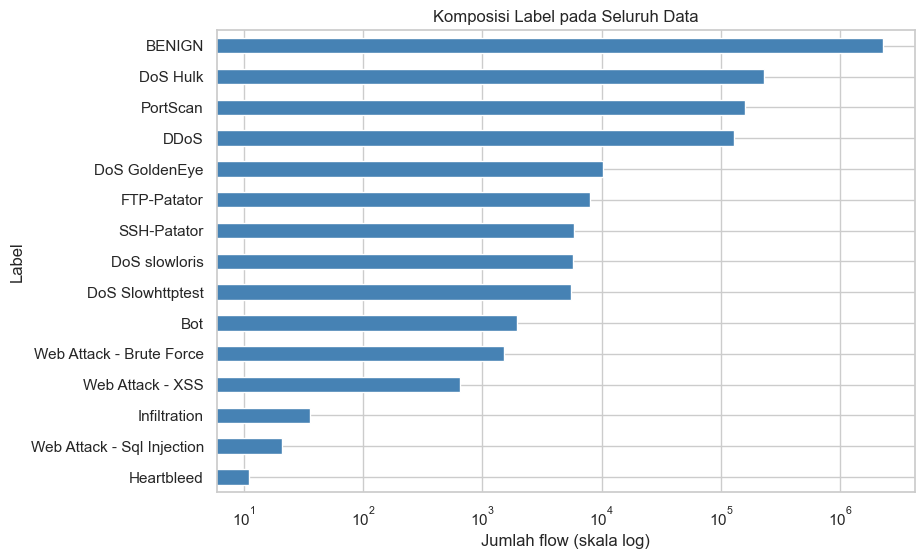

Lalu lintas normal: 80.3% | serangan: 19.7%


In [4]:
tot = counts.groupby('Label')['jumlah'].sum().sort_values()
plt.figure(figsize=(9,6)); tot.plot.barh(logx=True, color='steelblue')
plt.xlabel('Jumlah flow (skala log)'); plt.title('Komposisi Label pada Seluruh Data'); plt.show()
print(f"Lalu lintas normal: {tot['BENIGN']/tot.sum():.1%} | serangan: {1-tot['BENIGN']/tot.sum():.1%}")

**Temuan:** mayoritas lalu lintas adalah **BENIGN**, dan serangan terpusat pada hari tertentu: *FTP/SSH-Patator* (Selasa), keluarga *DoS* dan *Heartbleed* (Rabu), *Web Attack* dan *Infiltration* (Kamis), *Bot*, *PortScan*, dan *DDoS* (Jumat). Senin hanya berisi lalu lintas normal. Beberapa serangan sangat langka (*Heartbleed*, *SQL Injection*, *Infiltration*) sehingga sulit dideteksi, ini akan terlihat pada hasil model.

## 2. Pembersihan Data

In [5]:
df = df.replace([np.inf, -np.inf], np.nan)
print('Baris dengan NaN/Inf :', df.isna().any(axis=1).sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)
const = [c for c in df.columns.drop(['Label','Hari']) if df[c].nunique()==1]
print('Fitur konstan (tanpa informasi):', const)
df = df.drop(columns=const)
print('Ukuran setelah dibersihkan:', df.shape)

Baris dengan NaN/Inf : 232
Fitur konstan (tanpa informasi): ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Ukuran setelah dibersihkan: (244161, 72)


Kolom `Flow Bytes/s` dan `Flow Packets/s` berisi nilai tak hingga (*Inf*) akibat pembagian dengan durasi nol, sehingga baris tersebut dibuang. Fitur yang nilainya konstan dibuang karena tidak membawa informasi.

## 3. Eksplorasi: Apa yang Membedakan Serangan?

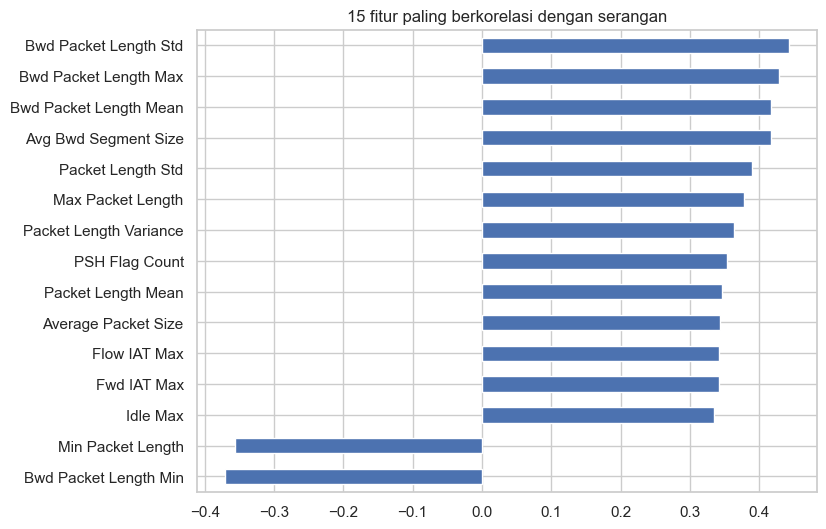

In [6]:
df['Serangan'] = (df['Label']!='BENIGN').astype(int)
fitur = [c for c in df.columns if c not in ['Label','Hari','Serangan']]
cor = df[fitur+['Serangan']].corr()['Serangan'].drop('Serangan')
top = cor.abs().sort_values(ascending=False).head(15)
cor[top.index].sort_values().plot.barh(figsize=(8,6), title='15 fitur paling berkorelasi dengan serangan'); plt.show()

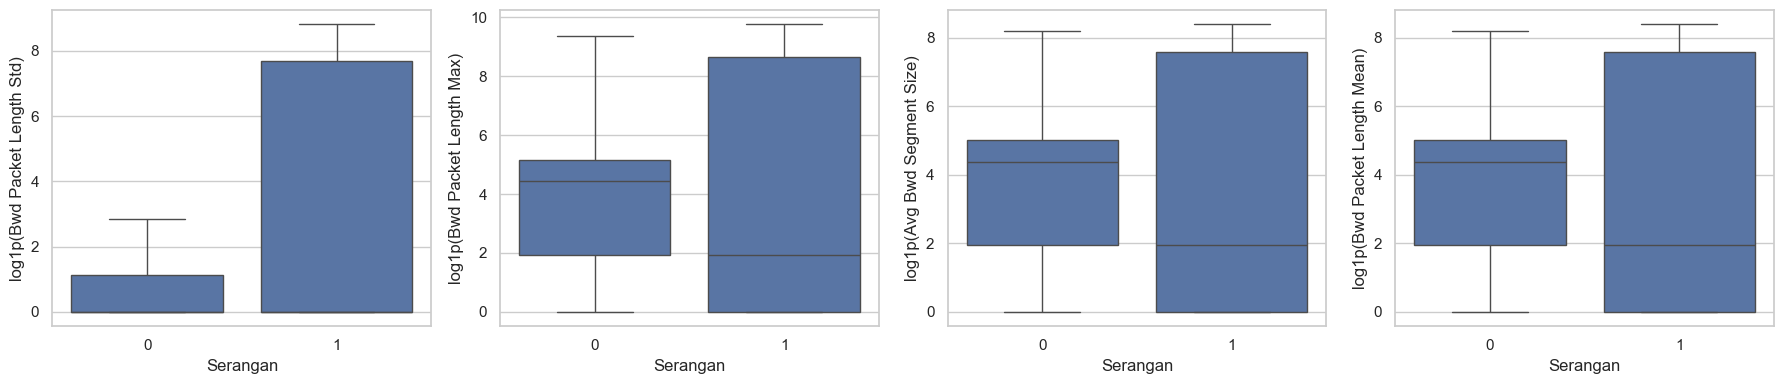

In [7]:
kunci = list(top.index[:4])
fig, axes = plt.subplots(1,4, figsize=(18,4))
for ax,c in zip(axes,kunci):
    sns.boxplot(data=df, x='Serangan', y=np.log1p(df[c].clip(lower=0)), ax=ax, showfliers=False); ax.set_ylabel('log1p('+c+')')
plt.tight_layout(); plt.show()

Grafik ini menunjukkan fitur (umumnya terkait **ukuran paket, durasi *flow*, dan *window size* TCP**) yang paling berbeda antara lalu lintas normal dan serangan. Nilai di-log agar skala yang timpang tetap terbaca.

## 4. Pemodelan Deteksi Serangan

In [8]:
X, y = df[fitur], df['Label']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
rf = RandomForestClassifier(n_estimators=100, max_depth=20, class_weight='balanced_subsample', n_jobs=-1, random_state=42)
rf.fit(Xtr, ytr); pred = rf.predict(Xte)
print(classification_report(yte, pred, zero_division=0, digits=3))

                            precision    recall  f1-score   support

                    BENIGN      0.999     0.993     0.996     47035
                       Bot      0.693     0.990     0.815       584
                      DDoS      1.000     1.000     1.000      6000
             DoS GoldenEye      0.998     0.999     0.998      3085
                  DoS Hulk      0.992     0.999     0.995      4606
          DoS Slowhttptest      0.998     0.996     0.997      1568
             DoS slowloris      0.998     0.995     0.996      1612
               FTP-Patator      1.000     1.000     1.000      1779
                Heartbleed      1.000     0.667     0.800         3
              Infiltration      1.000     1.000     1.000        11
                  PortScan      0.996     0.999     0.998      5357
               SSH-Patator      0.999     0.999     0.999       966
  Web Attack - Brute Force      0.756     0.696     0.725       441
Web Attack - Sql Injection      0.667     0.333

**Penting:** karena kelas BENIGN dan serangan besar dipangkas menjadi maksimal 20.000 baris per file, proporsi serangan di data kerja (± 36%) jauh lebih tinggi daripada aslinya (± 20%). Angka precision pada jaringan sungguhan akan lebih rendah karena alarm palsu lebih terasa saat lalu lintas normal jauh lebih dominan.

**Cara membaca:** perhatikan **recall per jenis serangan**. Serangan bervolume besar (DDoS, PortScan, DoS) biasanya terdeteksi hampir sempurna, sedangkan serangan langka atau mirip satu sama lain (*Web Attack* XSS, Brute Force, SQL Injection, *Bot*) lebih sulit. Ini wajar karena contoh latihnya sedikit dan polanya mirip. *Infiltration* dan *Heartbleed* tampak sempurna/tinggi hanya karena baris uji-nya amat sedikit (11 dan 3), sehingga angkanya belum bisa dipercaya.

Deteksi serangan vs normal (biner):
              precision    recall  f1-score   support

      Normal     0.9994    0.9932    0.9963     47035
    Serangan     0.9879    0.9990    0.9934     26214

    accuracy                         0.9952     73249
   macro avg     0.9936    0.9961    0.9948     73249
weighted avg     0.9953    0.9952    0.9952     73249



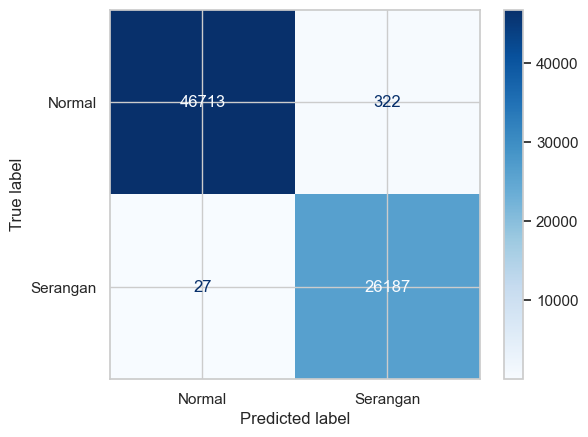

In [9]:
biner_true = (yte!='BENIGN'); biner_pred = (pd.Series(pred, index=yte.index)!='BENIGN')
print('Deteksi serangan vs normal (biner):')
print(classification_report(biner_true, biner_pred, target_names=['Normal','Serangan'], digits=4))
ConfusionMatrixDisplay(confusion_matrix(biner_true, biner_pred), display_labels=['Normal','Serangan']).plot(cmap='Blues'); plt.show()

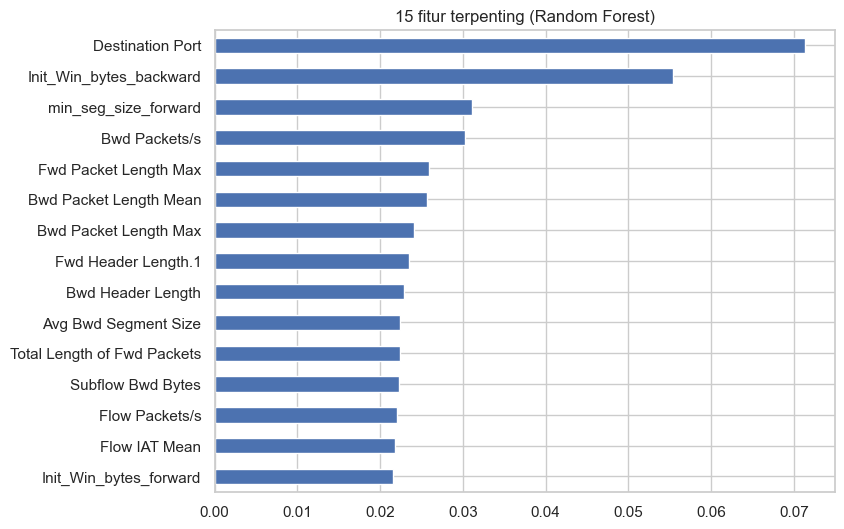

In [10]:
imp = pd.Series(rf.feature_importances_, index=fitur).sort_values(ascending=False).head(15)
imp.sort_values().plot.barh(figsize=(8,6), title='15 fitur terpenting (Random Forest)'); plt.show()

## 5. Kesimpulan
- Lalu lintas jaringan didominasi trafik normal; serangan terkonsentrasi pada hari dan jam tertentu sesuai skenario pengujian.
- Pembersihan penting dilakukan: nilai tak hingga, duplikat, dan fitur konstan dibuang.
- Random Forest memisahkan lalu lintas normal dari serangan dengan sangat baik (akurasi biner ± 99,5% pada data tersampel), sedangkan jenis *Web Attack* (F1 ± 0,45-0,73) dan *Bot* (precision ± 0,69) jauh lebih sulit, sehingga perlu data tambahan atau teknik *resampling* bila ingin mendeteksinya.
- Fitur terpenting (ukuran/panjang paket, durasi, IAT, *window size*) bisa dijadikan dasar aturan pemantauan pada IDS/IPS.